# 09 — Calibration between sessions and repeatability at the same spot

**What this notebook does**

1. compares the **calibration metadata** of the four groups (cantilever, spring constant, sensitivity, setpoint) and quantifies how much a calibration difference between sessions could shift $\log A$, to judge which comparisons are protected from it (within a session) and which are not (between lines);
2. uses the **bursts** of consecutive curves (≈ 2 s apart at the same spot, from notebook 08) to split the variance of $\log A$ into **measurement repeatability** and variation between spots and regions;
3. tests for a **preconditioning effect**: does the first curve at a spot differ systematically from the following ones (the cell softens or stiffens after the first indentation)?

**What it does NOT do**

- it does not re-calibrate anything: the spring constants and sensitivities are those stored in the JPK files;
- it does not remove or correct any curve in notebooks 02–08;
- bursts are a proxy of the spot, not of the cell identifier (unknown).

Region labels follow the data folders: `cito` = cytoplasm, `nucleo` = nucleus.

In [1]:
import warnings, json; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats
import afm_tools as T

T.set_plot_style()
SEED = 20261016; RNG = np.random.default_rng(SEED); summary = {}; lines = ["MCF7R", "T47DR"]
CAL_PATH = T.RESULTS_DIR / "session_calibration.csv"; META = T.OUTPUT_DIR / "metadata" / "metadata_segments.csv"
if META.exists():
    m = pd.read_csv(META); m = m[m.segment_id == 0]
    cal = m.groupby("group").agg(cantilever_id=("cantilever_id", "first"), cantilever_name=("cantilever_name", "first"), spring_N_per_m=("spring_N_per_m", "first"),
                                 sensitivity_nm_per_V=("sensitivity_m_per_V", lambda s: 1e9 * s.iloc[0]), setpoint_V=("setpoint", "first"), n_distinct_spring=("spring_N_per_m", "nunique"),
                                 n_distinct_sens=("sensitivity_m_per_V", "nunique"), median_points=("num_points_header", "median")).reset_index()
    cal.to_csv(CAL_PATH, index=False); print("rebuilt", CAL_PATH.name)
cal = pd.read_csv(CAL_PATH); cal["group_short"] = cal.group.map(T.short_group)
cal["force_per_volt_nN"] = cal.spring_N_per_m * cal.sensitivity_nm_per_V          # nN per V of deflection
cal["setpoint_force_nN"] = cal.force_per_volt_nN * cal.setpoint_V
cal.round(4).set_index("group_short").drop(columns="group")

rebuilt session_calibration.csv


,cantilever_id,cantilever_name,spring_N_per_m,sensitivity_nm_per_V,setpoint_V,n_distinct_spring,n_distinct_sens,median_points,force_per_volt_nN,setpoint_force_nN
group_short,,,,,,,,,,
MCF7R cito,2300FE,MLCT-BIO-Triangular,0.1188,10.9028,0.5789,1,1,6000.0,1.2956,0.75
MCF7R nucleo,2300FE,MLCT-BIO-Triangular,0.1188,10.9028,0.5789,1,1,6000.0,1.2956,0.75
T47DR cito,2300FE,MLCT-BIO-Triangular,0.0800,13.9963,0.6695,1,1,6000.0,1.1203,0.75
T47DR nucleo,2300FE,MLCT-BIO-Triangular,0.0800,13.9963,0.6695,1,1,6000.0,1.1203,0.75


## 1. Calibration of the four groups

The same cantilever (`2300FE`, MLCT-BIO) was used in both sessions, but the stored spring constant and sensitivity differ between the two days; within a session they are identical for cytoplasm and nucleus. The product $k\cdot S$ gives the force per volt of deflection signal, and $k\cdot S\cdot V_{setpoint}$ the force setpoint.

In [2]:
fit = T.load_fit_table(); fit = fit[fit.fit_status == "ok"]
fmax = fit.groupby("group").fmax_nN.agg(["median", "std"]); fmax["group_short"] = fmax.index.map(T.short_group)
k = {l: cal[cal.group_short.str.startswith(l)].spring_N_per_m.iloc[0] for l in lines}; S = {l: cal[cal.group_short.str.startswith(l)].sensitivity_nm_per_V.iloc[0] for l in lines}
sp = {l: cal[cal.group_short.str.startswith(l)].setpoint_force_nN.iloc[0] for l in lines}
dk = np.log(k["T47DR"] / k["MCF7R"]); dS = np.log(S["T47DR"] / S["MCF7R"]); dks = np.log((k["T47DR"] * S["T47DR"]) / (k["MCF7R"] * S["MCF7R"]))
summary["calibration"] = dict(spring=k, sensitivity_nm_per_V=S, setpoint_force_nN=sp, log_ratio_k=float(dk), log_ratio_S=float(dS), log_ratio_kS=float(dks), fmax_median_nN=fmax.set_index("group_short")["median"].round(3).to_dict())
print(f"k: MCF7R {k['MCF7R']:.4f}  T47DR {k['T47DR']:.4f} N/m  -> log ratio T47DR/MCF7R = {dk:+.3f} ({100 * (np.exp(dk) - 1):+.0f}%)")
print(f"S: MCF7R {S['MCF7R']:.2f}  T47DR {S['T47DR']:.2f} nm/V -> log ratio = {dS:+.3f}")
print(f"force setpoint: {sp['MCF7R']:.3f} nN (MCF7R) vs {sp['T47DR']:.3f} nN (T47DR); k*S ratio log = {dks:+.3f}")
print(fmax.round(3)[["group_short", "median", "std"]].to_string(index=False))

k: MCF7R 0.1188  T47DR 0.0800 N/m  -> log ratio T47DR/MCF7R = -0.395 (-33%)
S: MCF7R 10.90  T47DR 14.00 nm/V -> log ratio = +0.250
force setpoint: 0.750 nN (MCF7R) vs 0.750 nN (T47DR); k*S ratio log = -0.145
 group_short  median   std
  MCF7R cito   0.557 0.111
MCF7R nucleo   0.607 0.093
  T47DR cito   0.548 0.075
T47DR nucleo   0.533 0.084


**What it means for $\log A$.** The fitted force is proportional to the spring constant ($F=k\,S\,V$), so an error $\epsilon$ in $\ln k$ shifts $\ln A$ by the same $\epsilon$. The ratio of the two stored spring constants is $\ln(0.080/0.119)=-0.39$: a calibration uncertainty of this size is comparable to or larger than the observed differences **between lines**, so line differences in $A$ cannot be interpreted. Within a session the calibration is common to the two regions and cancels in $\Delta$, so the **nucleus–cytoplasm** comparison is protected from a calibration error (not from drift). We compare the line difference with the calibration band.

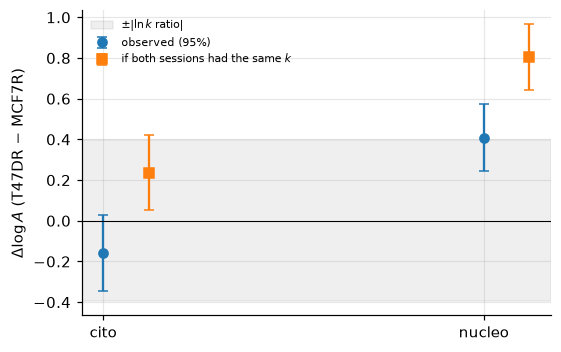

,delta_T47DR_minus_MCF7R,se,log_k_ratio,delta_if_k_equal,p_welch
region,,,,,
cito,-0.158,0.092,-0.395,0.237,0.089
nucleo,0.409,0.082,-0.395,0.804,0.000


In [3]:
ana = T.good_sample(fit); rows = []
for r_ in ["cito", "nucleo"]:
    xa = ana[(ana.cell_line == "MCF7R") & (ana.region == r_)].logA; xb = ana[(ana.cell_line == "T47DR") & (ana.region == r_)].logA
    rows.append(dict(region=r_, delta_T47DR_minus_MCF7R=xb.mean() - xa.mean(), se=np.hypot(xa.sem(), xb.sem()), log_k_ratio=dk,
                     delta_if_k_equal=xb.mean() - xa.mean() - dk, p_welch=stats.ttest_ind(xb, xa, equal_var=False).pvalue))
line_tab = pd.DataFrame(rows).set_index("region"); summary["line_difference_vs_calibration"] = line_tab.round(4).to_dict("index")
fig, ax = plt.subplots(figsize=(5.5, 3.6)); x = np.arange(2)
ax.errorbar(x, line_tab.delta_T47DR_minus_MCF7R, 2 * line_tab.se, fmt="o", capsize=3, label="observed (95%)")
ax.errorbar(x + .12, line_tab.delta_if_k_equal, 2 * line_tab.se, fmt="s", capsize=3, label=r"if both sessions had the same $k$")
ax.axhline(0, c="k", lw=.7); ax.axhspan(-abs(dk), abs(dk), color="gray", alpha=.12, label=r"$\pm|\ln k$ ratio$|$")
ax.set_xticks(x, ["cito", "nucleo"]); ax.set_ylabel(r"$\Delta\log A$ (T47DR − MCF7R)"); ax.legend(fontsize=7); plt.show(); line_tab.round(3)

## 2. Repeatability at the same spot

Bursts are defined as in notebook 08 (gap > 10 s starts a new burst). For each group the variance of $\log A$ is split with a one-way random-effects decomposition: **within-burst** (curves at the same spot, a few seconds apart: repeatability, including real changes in the cell) and **between-burst** (different spots). Both are compared with the total spread and with the region difference.

In [4]:
times = pd.read_csv(T.RESULTS_DIR / "acquisition_times.csv", parse_dates=["t"])
df = fit.merge(times, on=["file_name", "group"]).sort_values(["cell_line", "region", "t"]).reset_index(drop=True)
df["gap_s"] = df.groupby(["cell_line", "region"]).t.diff().dt.total_seconds()
df["burst"] = df.groupby(["cell_line", "region"], group_keys=False).apply(lambda d: ((d.gap_s.isna()) | (d.gap_s > 10)).cumsum())
df["cluster"] = df.cell_line + "_" + df.region + "_" + df.burst.astype(str); df["pos"] = df.groupby("cluster").cumcount() + 1; df["burst_size"] = df.groupby("cluster").logA.transform("size")
def components(d, col="logA"):
    g = d.groupby("cluster")[col]; k = g.ngroups; n = len(d); ni = g.size().to_numpy(); mu = d[col].mean()
    ssb = (ni * (g.mean().to_numpy() - mu) ** 2).sum(); ssw = ((d[col] - g.transform("mean")) ** 2).sum(); msb, msw = ssb / (k - 1), ssw / (n - k); m0 = (n - (ni ** 2).sum() / n) / (k - 1)
    return msw, max((msb - msw) / m0, 0.0)
rows = []
for (l, r_), d in df.groupby(["cell_line", "region"]):
    w, b = components(d); rows.append(dict(line=l, region=r_, n=len(d), bursts=d.cluster.nunique(), sd_within_burst=np.sqrt(w), sd_between_burst=np.sqrt(b), sd_total=d.logA.std(), repeatability_fraction=w / (w + b)))
var = pd.DataFrame(rows).set_index(["line", "region"]); summary["variance_components"] = {f"{k[0]}|{k[1]}": v for k, v in var.round(4).to_dict("index").items()}; var.round(3)

n  bursts  sd_within_burst  sd_between_burst  sd_total  \
line  region                                                            
MCF7R cito    55      16            0.435             0.202     0.477   
      nucleo  60      13            0.335             0.000     0.327   
T47DR cito    59      17            0.462             0.218     0.508   
      nucleo  83      16            0.606             0.202     0.637   

              repeatability_fraction  
line  region                          
MCF7R cito                     0.823  
      nucleo                   1.000  
T47DR cito                     0.818  
      nucleo                   0.900

## 3. Preconditioning: is the first curve at a spot different?

Within each burst we subtract the burst mean and look at $\log A$ as a function of the **position** in the burst (1st, 2nd, 3rd, ...), pooling bursts of at least 3 curves, with a bootstrap over bursts. We also test the paired difference *second − first curve* of each burst. A systematic change (for example a decrease after the first indentation) would indicate that the cell is modified by the measurement and that the first curve is not representative.

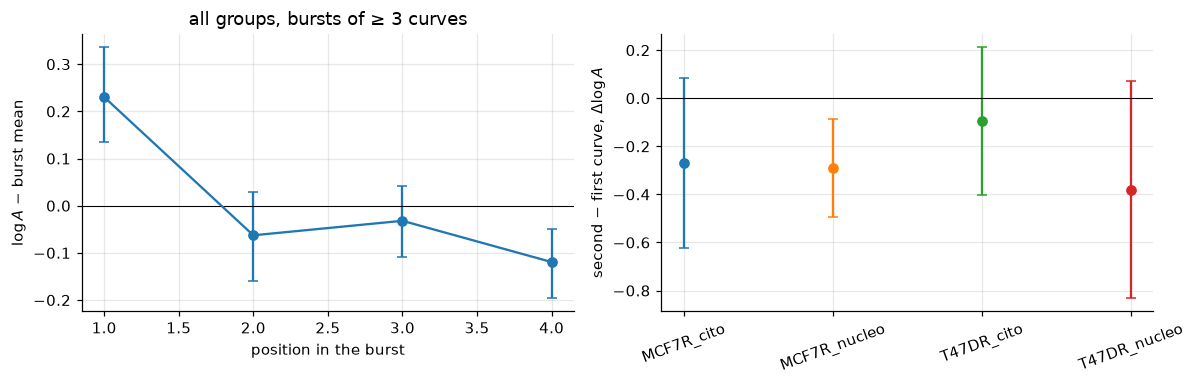

,n_pairs,mean_second_minus_first,sem,p_wilcoxon
group,,,,
MCF7R_cito,15,-0.2700,0.1799,0.2524
MCF7R_nucleo,13,-0.2918,0.1041,0.0171
T47DR_cito,17,-0.0933,0.1569,0.5791
T47DR_nucleo,16,-0.3799,0.2310,0.1928
all,61,-0.2542,0.0886,0.0126


In [5]:
big = df[df.burst_size >= 3].copy(); big["dev"] = big.logA - big.groupby("cluster").logA.transform("mean"); POS = [1, 2, 3, 4]
rows = []
for (l, r_), d in list(big.groupby(["cell_line", "region"])) + [(("all", "all"), big)]:
    for p in POS:
        s = d[d.pos == p]; cl = d.cluster.unique(); bs = [d[(d.pos == p) & d.cluster.isin(RNG.choice(cl, len(cl)))].dev.mean() for _ in range(500)]
        rows.append(dict(line=l, region=r_, position=p, n=len(s), mean_dev=s.dev.mean(), lo95=np.nanquantile(bs, .025), hi95=np.nanquantile(bs, .975)))
pos_tab = pd.DataFrame(rows); summary["position_effect"] = pos_tab.round(4).to_dict("records")
first = df[df.pos == 1].set_index("cluster").logA; second = df[(df.pos == 2)].set_index("cluster").logA; pair = (second - first).dropna()
by = {k_: (second - first).dropna()[[c for c in (second - first).dropna().index if c.startswith(k_)]] for k_ in ["MCF7R_cito", "MCF7R_nucleo", "T47DR_cito", "T47DR_nucleo"]}
rows = [dict(group=k_, n_pairs=len(v), mean_second_minus_first=v.mean(), sem=v.sem(), p_wilcoxon=stats.wilcoxon(v).pvalue) for k_, v in by.items()] + [dict(group="all", n_pairs=len(pair), mean_second_minus_first=pair.mean(), sem=pair.sem(), p_wilcoxon=stats.wilcoxon(pair).pvalue)]
pairs = pd.DataFrame(rows).set_index("group"); summary["second_minus_first"] = pairs.round(4).to_dict("index")
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6)); a_ = pos_tab[(pos_tab.line == "all")]
ax[0].errorbar(a_.position, a_.mean_dev, [a_.mean_dev - a_.lo95, a_.hi95 - a_.mean_dev], marker="o", capsize=3); ax[0].axhline(0, c="k", lw=.7); ax[0].set_xlabel("position in the burst"); ax[0].set_ylabel(r"$\log A$ − burst mean"); ax[0].set_title("all groups, bursts of ≥ 3 curves")
for k_, c in zip(by, ["C0", "C1", "C2", "C3"]): ax[1].errorbar([k_], [by[k_].mean()], [by[k_].sem() * 1.96], marker="o", c=c, capsize=3)
ax[1].axhline(0, c="k", lw=.7); ax[1].set_ylabel(r"second − first curve, $\Delta\log A$"); plt.setp(ax[1].get_xticklabels(), rotation=20); plt.tight_layout(); plt.show(); pairs.round(4)

## 4. Does the burst structure bias the nucleus–cytoplasm difference?

If later curves in a burst are softer (section 3) and the nucleus has longer bursts than the cytoplasm (≈ 5 against ≈ 3.5 curves), the nucleus mean contains more of the softened curves and $\Delta$ is biased towards "softer nucleus". Three checks per line: (a) $\Delta$ from the **first curve of each burst only** (one curve per spot, free of preconditioning and of burst length); (b) all curves with **position fixed effects** (1st, 2nd, 3rd, ≥ 4th); (c) as (b) plus the common **time trend** of notebook 08. Standard errors are clustered on the bursts.

In [6]:
def ols_cluster(d, cols_extra, label):
    X = np.c_[np.ones(len(d)), (d.region == "nucleo").astype(float)] if not cols_extra else np.c_[np.ones(len(d)), (d.region == "nucleo").astype(float), d[cols_extra].to_numpy(float)]
    y = d.logA.to_numpy(); beta = np.linalg.lstsq(X, y, rcond=None)[0]; res = y - X @ beta; XtXi = np.linalg.pinv(X.T @ X)
    meat = sum(np.outer(X[i].T @ res[i], X[i].T @ res[i]) for i in d.groupby("cluster").indices.values()); G = d.cluster.nunique(); V = XtXi @ meat @ XtXi * G / (G - 1)
    return dict(model=label, delta=beta[1], se=np.sqrt(V[1, 1]), p=2 * stats.t.sf(abs(beta[1] / np.sqrt(V[1, 1])), df=G - X.shape[1]), n=len(d), bursts=G)
df["pos2"] = (df.pos == 2).astype(float); df["pos3"] = (df.pos == 3).astype(float); df["pos4p"] = (df.pos >= 4).astype(float)
df["t_min"] = df.groupby("cell_line").t.transform(lambda s: (s - s.min()).dt.total_seconds() / 60)
rows = []
for l in lines:
    d = df[df.cell_line == l]; f1 = d[d.pos == 1]
    rows.append(dict(line=l, **ols_cluster(d, [], "all curves")))
    rows.append(dict(line=l, **ols_cluster(f1, [], "first curve of each burst")))
    rows.append(dict(line=l, **ols_cluster(d, ["pos2", "pos3", "pos4p"], "all curves + position effects")))
    rows.append(dict(line=l, **ols_cluster(d, ["pos2", "pos3", "pos4p", "t_min"], "all curves + position + time trend")))
    rows.append(dict(line=l, **ols_cluster(f1, ["t_min"], "first curve + time trend")))
burst_bias = pd.DataFrame(rows).set_index(["line", "model"]); summary["delta_burst_bias"] = {f"{k[0]}|{k[1]}": v for k, v in burst_bias.round(5).to_dict("index").items()}
sz = df.groupby(["cell_line", "region"]).burst_size.mean(); summary["mean_burst_size"] = {f"{k[0]}|{k[1]}": float(v) for k, v in sz.items()}; print("mean burst size:", sz.round(2).to_dict()); burst_bias.round(4)

mean burst size: {('MCF7R', 'cito'): 3.91, ('MCF7R', 'nucleo'): 5.2, ('T47DR', 'cito'): 4.22, ('T47DR', 'nucleo'): 5.94}


delta      se       p    n  bursts
line  model                                                                  
MCF7R all curves                         -0.8139  0.0811  0.0000  115      29
      first curve of each burst          -0.7646  0.1316  0.0000   29      29
      all curves + position effects      -0.8071  0.0844  0.0000  115      29
      all curves + position + time trend -0.9791  0.1725  0.0000  115      29
      first curve + time trend           -0.1085  0.2654  0.6860   29      29
T47DR all curves                         -0.2468  0.1118  0.0349  142      33
      first curve of each burst          -0.0051  0.2622  0.9847   33      33
      all curves + position effects      -0.1879  0.1193  0.1265  142      33
      all curves + position + time trend  0.0572  0.1800  0.7530  142      33
      first curve + time trend            0.1820  0.4145  0.6639   33      33

In [7]:
json.dump(summary, open(T.RESULTS_DIR / "09_summary.json", "w"), indent=1, default=float)

## Interpretation and limits

- **Calibration.** The same cantilever was used in both sessions, but its stored spring constant differs by 40% ($0.119$ against $0.080$ N/m; $\ln$ ratio $-0.40$) and the sensitivity by 28%. The force *setpoint* is identical (0.75 nN), so the experimenters set it in force units. A calibration uncertainty of this size shifts $\ln A$ by up to $0.4$, as large as the observed line differences ($-0.16$ in the cytoplasm, $+0.41$ in the nucleus; $+0.24$ and $+0.80$ if both sessions had the same $k$): **differences between lines cannot be interpreted**, not even in sign. Within a session the calibration is common to the two regions and cancels in $\Delta$, so the nucleus–cytoplasm comparison is protected from calibration errors.
- **Repeatability.** Curves taken a few seconds apart at the same spot differ by $\mathrm{sd}\approx0.33$–$0.61$ in $\log A$ (a factor 1.4–1.8), 80–100% of the total variance: the measurement-to-measurement scatter at one spot is as large as the scatter between spots. The precision of one curve is the limiting factor, which also explains why the intra-burst correlation is low.
- **Preconditioning.** The first curve at a spot has $\log A$ about $0.23$ above the burst mean and the later ones are lower; the paired difference second − first is $-0.25\pm0.09$ ($p=0.013$, 61 bursts), with the same sign in all four groups. The indentation therefore **modifies the cell** (softening after the first contact, or a transient), and the first curve is the only one representative of the unperturbed state.
- **Bias of the region difference.** The nucleus bursts are longer than the cytoplasm ones (≈ 4.6–5.2 against ≈ 3.4–3.5 curves per burst, notebook 08), so the nucleus mean contains more softened curves. Using only the **first curve of each burst**: MCF7R $\Delta=-0.77\pm0.13$ (unchanged, $p<10^{-3}$); T47DR $\Delta=-0.01\pm0.26$ ($p=0.99$), which is compatible both with no effect and with the earlier $-0.25$ because only 33 curves remain. With position fixed effects T47DR gives $-0.19\pm0.12$ ($p=0.13$), and with position and time trend together $+0.06\pm0.18$. The MCF7R result survives every correction (with the time trend it becomes $-0.98\pm0.17$); the T47DR stiffness difference does not.
- **Limits.** Bursts are a proxy for the spot, not the cell identifier. The first-curve-only analysis has little power for T47DR (SE 0.26), so it does not prove the absence of an effect, only that these data cannot establish it. The calibration values are those stored in the files; no independent calibration is available.

## Output produced

```text
results/session_calibration.csv   cantilever, spring constant, sensitivity, setpoint per group (tracked)
results/09_summary.json           calibration shift, variance components, position-in-burst effect
```